<a href="https://colab.research.google.com/github/ThePretelR/cassava-disease-model-comparison/blob/main/notebooks/07_experimento_robustez.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07 — Experimento controlado de robustez
Comparación pareada de imágenes originales y con brillo multiplicado por 0.8. Sin reentrenamiento.

**Hipótesis previa:** reducir el brillo puede disminuir Macro-F1 al dificultar la identificación de síntomas. La magnitud del efecto puede variar entre arquitecturas.

## 1. Entorno y configuración

In [4]:
%pip -q install tensorflow-datasets importlib_resources psutil

In [5]:
import os, gc, time, hashlib, json, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 8
CLASS_NAMES = ["cbb", "cbsd", "cgm", "cmd", "healthy"]
MODELS = ["E0", "E1", "E2", "E3"]
OUTPUT_DIR = Path("results/robustez")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)
print(tf.__version__, tf.config.list_physical_devices("GPU"))
FACTOR = 0.8

2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Carga de checkpoints
Se utilizan directamente los cuatro archivos `.keras` existentes en `/content/`, sin volver a subirlos.

In [6]:
from google.colab import files

MODEL_DIR = Path("/content")
RUTAS = {m: MODEL_DIR / f"mejor_modelo_{m.lower()}.keras" for m in MODELS}
faltantes = [str(p) for p in RUTAS.values() if not p.is_file()]
if faltantes:
    raise FileNotFoundError("Archivos faltantes: " + ", ".join(faltantes))

for nombre, ruta in RUTAS.items():
    print(f"{nombre}: {ruta} | {ruta.stat().st_size / 1024**2:.2f} MiB")

E0: /content/mejor_modelo_e0.keras | 1.31 MiB
E1: /content/mejor_modelo_e1.keras | 11.07 MiB
E2: /content/mejor_modelo_e2.keras | 20.18 MiB
E3: /content/mejor_modelo_e3.keras | 93.63 MiB


## 3. Partición de prueba e integridad

In [7]:
URL = "https://raw.githubusercontent.com/ThePretelR/cassava-disease-model-comparison/main/results/eda/manifiesto_final_conservados.csv"
manifest = pd.read_csv(URL)
assert len(manifest) == 9361
assert not manifest.duplicated(["particion", "indice"]).any()
prueba = manifest.loc[manifest.particion == "test"].sort_values("indice")
assert len(prueba) == 1874
raw, info = tfds.load("cassava:0.1.0", split="test", as_supervised=True, with_info=True, shuffle_files=False)
assert list(info.features["label"].names) == CLASS_NAMES
esperados = prueba.set_index("indice")
indices = set(esperados.index.astype(int))
assert min(indices) >= 0 and max(indices) < 1885
verificados = 0
for i, (img, y) in enumerate(raw):
    if i in indices:
        a = img.numpy()
        h = hashlib.sha256(str(a.shape).encode("utf-8") + a.tobytes()).hexdigest()
        assert h == esperados.loc[i, "hash"], f"Hash distinto: {i}"
        assert CLASS_NAMES[int(y.numpy())] == esperados.loc[i, "clase"]
        verificados += 1
assert verificados == 1874
mascara = tf.constant([i in indices for i in range(1885)])
test = (raw.enumerate().filter(lambda i, d: tf.gather(mascara, i))
        .map(lambda i, d: d, num_parallel_calls=1)
        .apply(tf.data.experimental.assert_cardinality(1874)))
print("Imágenes verificadas:", verificados)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-test.tfrecord-[0-9][0-9][0-9][0-9]…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-validation.tfrecord-[0-9][0-9][0-9…

Dataset cassava downloaded and prepared to /root/tensorflow_datasets/cassava/0.1.0. Subsequent calls will reuse this data.
Imágenes verificadas: 1874


## 4. Pipeline y evidencia visual
La perturbación se aplica a los píxeles redimensionados en [0,255], antes de la normalización. No se modifica el dataset original.

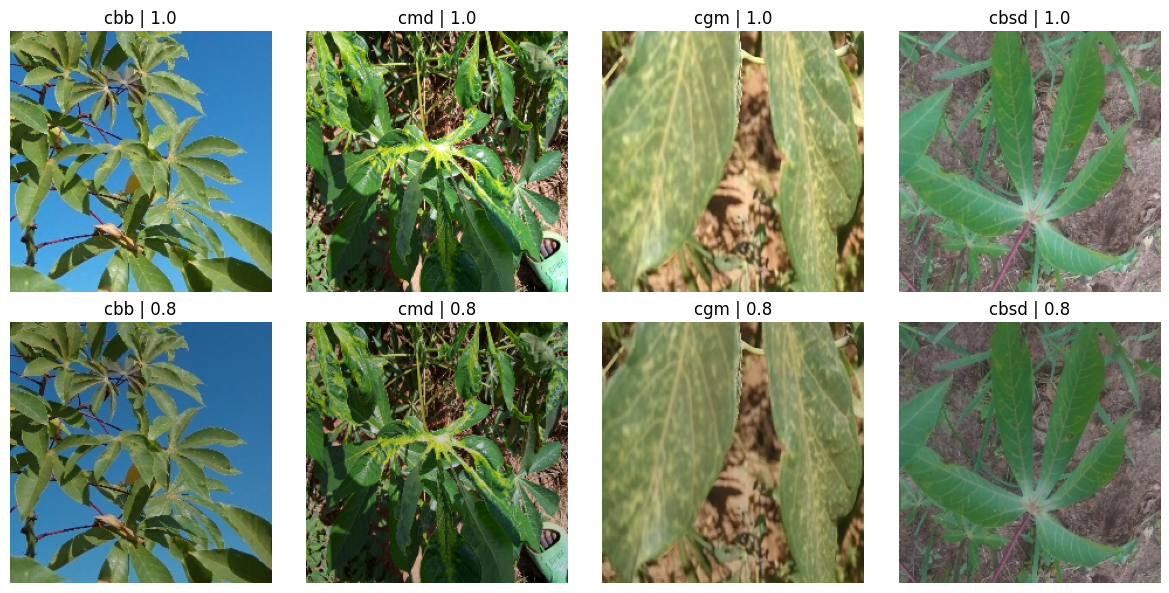

In [8]:
def preparar(img, y):
    return tf.cast(tf.image.resize(img, IMG_SIZE, method="bilinear"), tf.float32), tf.cast(y, tf.int32)
base_test = test.map(preparar, num_parallel_calls=2).batch(BATCH_SIZE).prefetch(1)
y_true = np.concatenate([y.numpy() for _, y in base_test])
assert np.array_equal(y_true, prueba.clase.map(CLASS_NAMES.index).to_numpy())

def dataset_modelo(nombre, factor):
    def transformar(x, y):
        x = tf.clip_by_value(x * factor, 0., 255.)
        return (x / 255.0 if nombre == "E0" else x), y
    return base_test.map(transformar, num_parallel_calls=1)

x, y = next(iter(base_test))
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for j in range(4):
    for i, factor in enumerate([1., FACTOR]):
        axes[i,j].imshow(tf.clip_by_value(x[j]*factor/255., 0., 1.).numpy())
        axes[i,j].set_title(f"{CLASS_NAMES[int(y[j])]} | {factor}")
        axes[i,j].axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "ejemplos_brillo.png", dpi=180)
plt.show()
plt.close(fig)

## 5. Evaluación pareada
Se recalcula el control original en la misma sesión para aislar el efecto del brillo. Se conserva el orden de las imágenes y se carga un modelo a la vez.

235/235 ━━━━━━━━━━━━━━━━━━━━ 23s 67ms/step


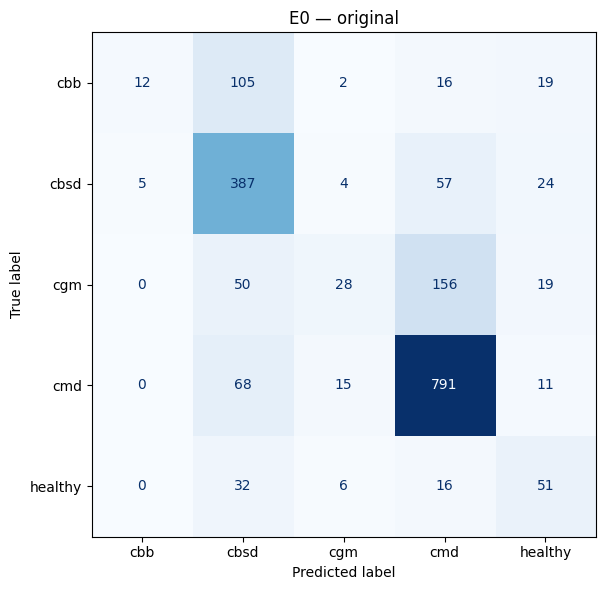

235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step


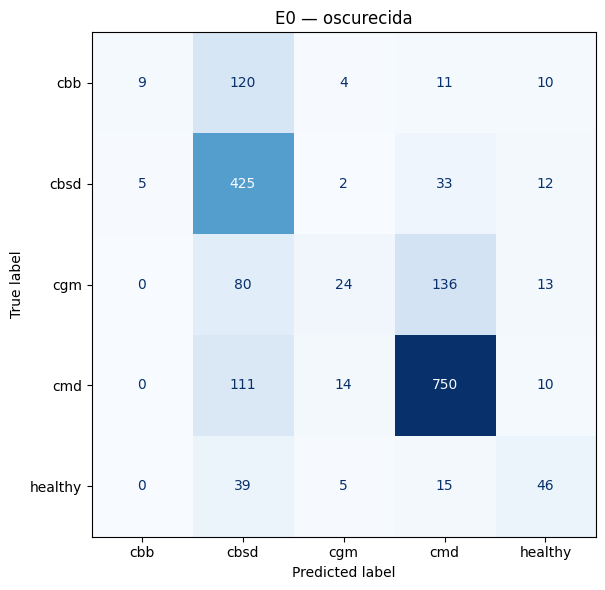

235/235 ━━━━━━━━━━━━━━━━━━━━ 46s 110ms/step


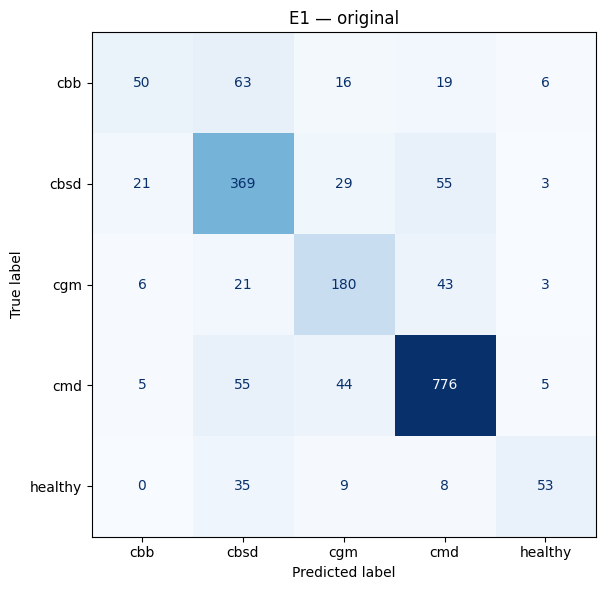

235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step


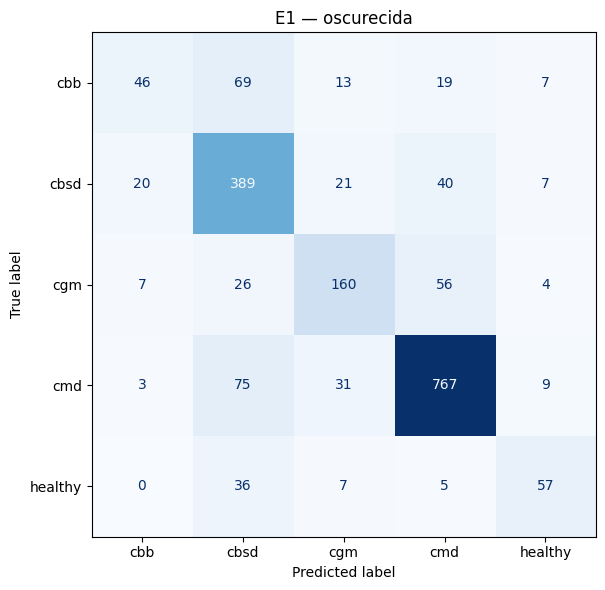

235/235 ━━━━━━━━━━━━━━━━━━━━ 15s 46ms/step


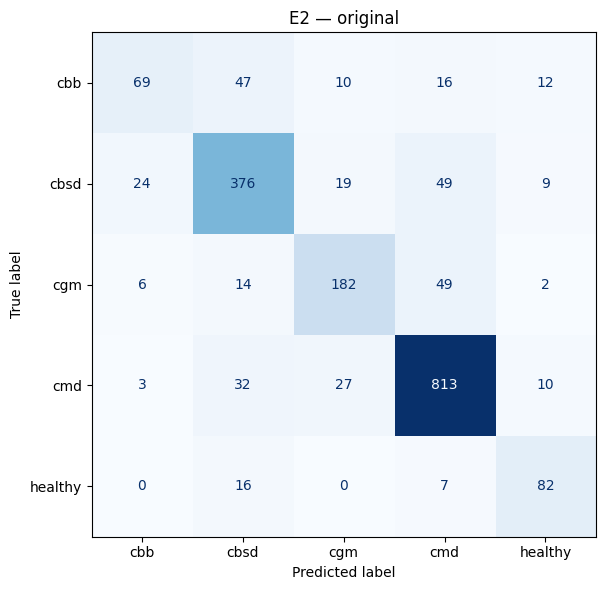

235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step


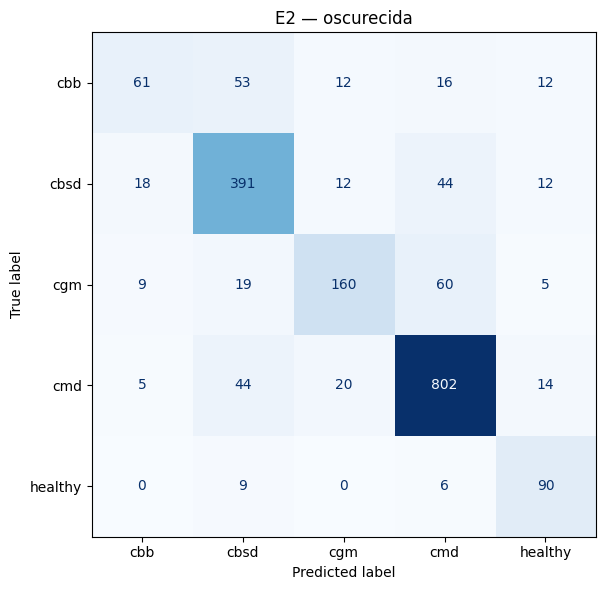

235/235 ━━━━━━━━━━━━━━━━━━━━ 40s 100ms/step


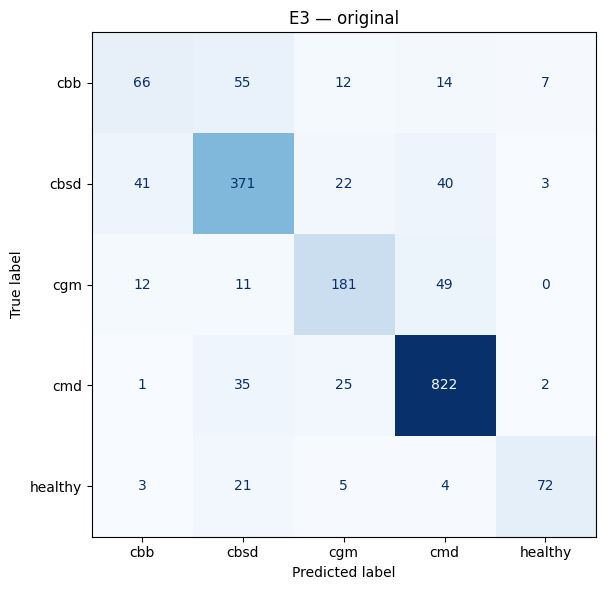

235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step


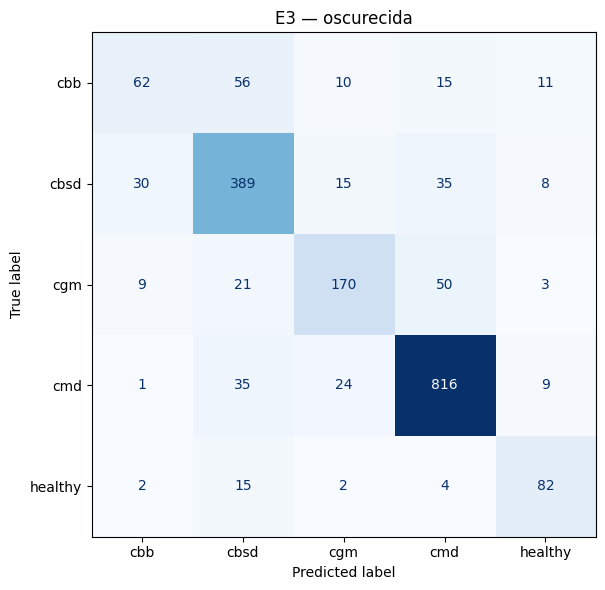

In [9]:
filas, reportes = [], []
for nombre in MODELS:
    tf.keras.backend.clear_session()
    modelo = tf.keras.models.load_model(RUTAS[nombre], compile=False)
    assert tuple(modelo.input_shape[1:]) == (224,224,3)
    assert modelo.output_shape[-1] == 5
    datos = pd.DataFrame({"indice_original": prueba.indice.to_numpy(), "real": y_true})
    for condicion, factor in [("original", 1.), ("oscurecida", FACTOR)]:
        ds = dataset_modelo(nombre, factor)
        probs = modelo.predict(ds, verbose=1)
        assert probs.shape == (1874,5) and np.isfinite(probs).all()
        np.testing.assert_allclose(probs.sum(axis=1), 1, atol=1e-4)
        pred = probs.argmax(axis=1)
        filas.append({"modelo": nombre, "condicion": condicion, "accuracy": accuracy_score(y_true,pred), "macro_f1": f1_score(y_true,pred,labels=range(5),average="macro",zero_division=0)})
        reporte = pd.DataFrame(classification_report(y_true,pred,labels=range(5),target_names=CLASS_NAMES,output_dict=True,zero_division=0)).T
        reporte.to_csv(OUTPUT_DIR / f"reporte_{nombre.lower()}_{condicion}.csv")
        clases = reporte.loc[CLASS_NAMES].reset_index(names="clase")
        clases.insert(0,"condicion",condicion)
        clases.insert(0,"modelo",nombre)
        reportes.append(clases)
        matriz = confusion_matrix(y_true,pred,labels=range(5))
        pd.DataFrame(matriz,index=CLASS_NAMES,columns=CLASS_NAMES).to_csv(OUTPUT_DIR / f"matriz_{nombre.lower()}_{condicion}.csv")
        fig, ax = plt.subplots(figsize=(7,6))
        ConfusionMatrixDisplay(matriz,display_labels=CLASS_NAMES).plot(ax=ax,cmap="Blues",colorbar=False,values_format="d")
        ax.set_title(f"{nombre} — {condicion}")
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / f"matriz_{nombre.lower()}_{condicion}.png",dpi=180)
        plt.show()
        plt.close(fig)
        datos[f"pred_{condicion}"] = pred
        datos[f"confianza_{condicion}"] = probs.max(axis=1)
    datos.to_csv(OUTPUT_DIR / f"predicciones_{nombre.lower()}.csv",index=False)
    del modelo, ds, probs, pred
    gc.collect()
    tf.keras.backend.clear_session()

## 6. Comparación de robustez
Delta = oscurecida − original. Un delta negativo indica deterioro. Los puntos porcentuales equivalen al delta multiplicado por 100.

In [10]:
metricas = pd.DataFrame(filas)
clases = pd.concat(reportes,ignore_index=True)
metricas.to_csv(OUTPUT_DIR / "metricas_globales.csv",index=False)
clases.to_csv(OUTPUT_DIR / "metricas_por_clase.csv",index=False)
comparacion = metricas.pivot(index="modelo",columns="condicion",values=["accuracy","macro_f1"])
comparacion.columns = [f"{a}_{b}" for a,b in comparacion.columns]
for metrica in ["accuracy","macro_f1"]:
    comparacion[f"delta_{metrica}"] = comparacion[f"{metrica}_oscurecida"] - comparacion[f"{metrica}_original"]
comparacion.to_csv(OUTPUT_DIR / "comparacion_robustez.csv")
display(comparacion.round(4))
por_clase = clases.pivot(index=["modelo","clase"],columns="condicion",values=["f1-score","recall"])
por_clase.columns = [f"{a}_{b}" for a,b in por_clase.columns]
for metrica in ["f1-score","recall"]:
    por_clase[f"delta_{metrica}"] = por_clase[f"{metrica}_oscurecida"] - por_clase[f"{metrica}_original"]
por_clase.to_csv(OUTPUT_DIR / "comparacion_por_clase.csv")
display(por_clase.round(4))
referencia = pd.Series({"E0":.4566,"E1":.6600,"E2":.7403,"E3":.7273})
control = pd.DataFrame({"macro_f1_previo":referencia,"macro_f1_actual":comparacion.macro_f1_original})
control["delta"] = control.macro_f1_actual - control.macro_f1_previo
control.to_csv(OUTPUT_DIR / "verificacion_control.csv")
display(control.round(6))
if (control.delta.abs() > .0001).any():
    print("Advertencia: revisar diferencias con la evaluación previa antes de interpretar.")

,accuracy_original,accuracy_oscurecida,macro_f1_original,macro_f1_oscurecida,delta_accuracy,delta_macro_f1
modelo,,,,,,
E0,0.6772,0.6692,0.4566,0.4468,-0.0080,-0.0097
E1,0.7620,0.7572,0.6600,0.6509,-0.0048,-0.0091
E2,0.8122,0.8026,0.7403,0.7245,-0.0096,-0.0158
E3,0.8068,0.8106,0.7273,0.7276,0.0037,0.0003


f1-score_original  f1-score_oscurecida  recall_original  \
modelo clase                                                              
E0     cbb                 0.1404               0.1071           0.0779   
       cbsd                0.6917               0.6789           0.8113   
       cgm                 0.1818               0.1589           0.1107   
       cmd                 0.8235               0.8197           0.8938   
       healthy             0.4454               0.4694           0.4857   
E1     cbb                 0.4237               0.4000           0.3247   
       cbsd                0.7235               0.7257           0.7736   
       cgm                 0.6780               0.6598           0.7115   
       cmd                 0.8690               0.8657           0.8768   
       healthy             0.6057               0.6032           0.5048   
E2     cbb                 0.5391               0.4939           0.4481   
       cbsd                0.7817               0.7875           0.7883   
       cgm                 0.7413               0.7002           0.7194   
       cmd                 0.8939               0.8847           0.9186   
       healthy             0.7455               0.7563           0.7810   
E3     cbb                 0.4765               0.4806           0.4286   
       cbsd                0.7649               0.7835           0.7778   
       cgm                 0.7269               0.7173           0.7154   
       cmd                 0.9063               0.9042           0.9288   
       healthy             0.7619               0.7523           0.6857   

                recall_oscurecida  delta_f1-score  delta_recall  
modelo clase                                                     
E0     cbb                 0.0584         -0.0332       -0.0195  
       cbsd                0.8910         -0.0128        0.0797  
       cgm                 0.0949         -0.0229       -0.0158  
       cmd                 0.8475         -0.0039       -0.0463  
       healthy             0.4381          0.0240       -0.0476  
E1     cbb                 0.2987         -0.0237       -0.0260  
       cbsd                0.8155          0.0022        0.0419  
       cgm                 0.6324         -0.0182       -0.0791  
       cmd                 0.8667         -0.0033       -0.0102  
       healthy             0.5429         -0.0025        0.0381  
E2     cbb                 0.3961         -0.0451       -0.0519  
       cbsd                0.8197          0.0058        0.0314  
       cgm                 0.6324         -0.0411       -0.0870  
       cmd                 0.9062         -0.0092       -0.0124  
       healthy             0.8571          0.0108        0.0762  
E3     cbb                 0.4026          0.0041       -0.0260  
       cbsd                0.8155          0.0185        0.0377  
       cgm                 0.6719         -0.0096       -0.0435  
       cmd                 0.9220         -0.0021       -0.0068  
       healthy             0.7810         -0.0096        0.0952

,macro_f1_previo,macro_f1_actual,delta
E0,0.4566,0.456560,-0.000040
E1,0.6600,0.659984,-0.000016
E2,0.7403,0.740293,-0.000007
E3,0.7273,0.727316,0.000016


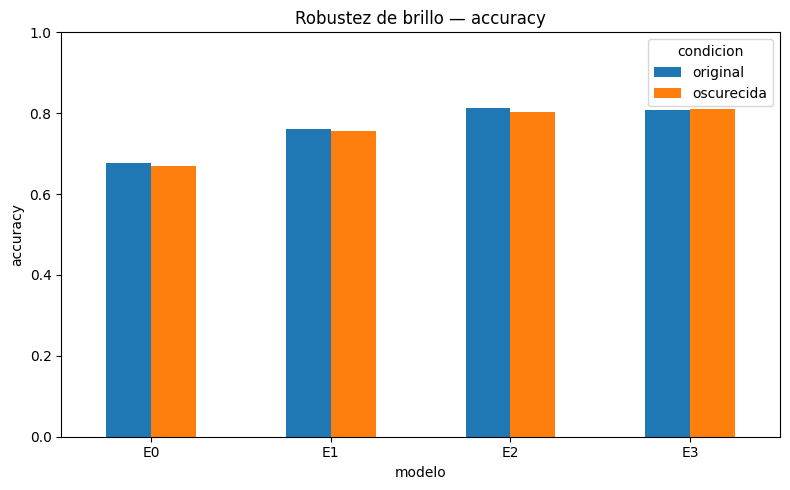

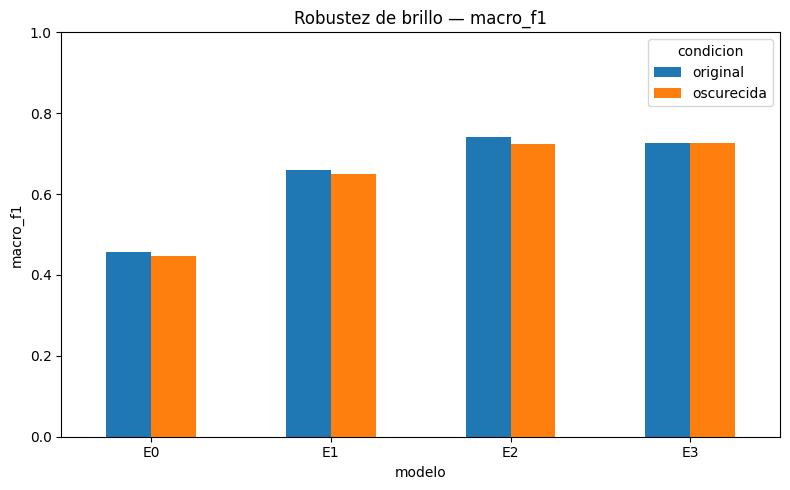

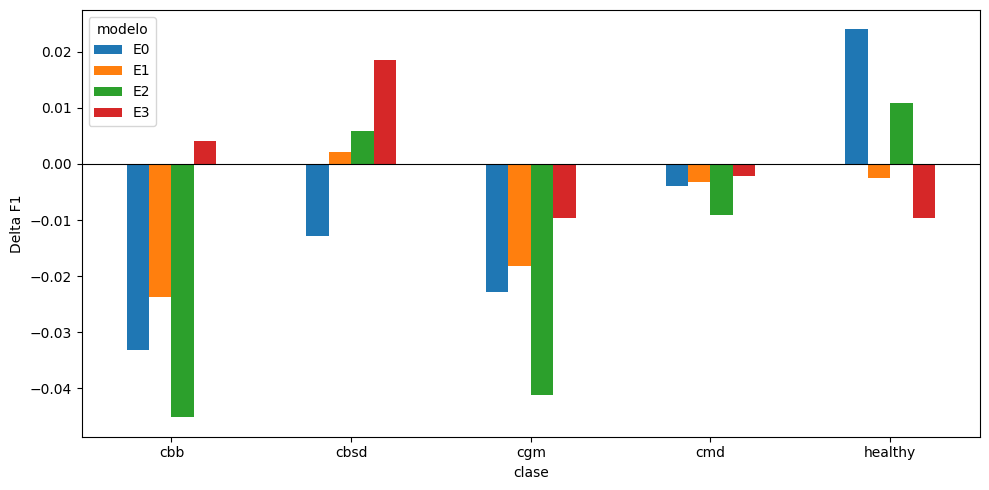

In [11]:
for metrica in ["accuracy","macro_f1"]:
    ax = metricas.pivot(index="modelo",columns="condicion",values=metrica)[["original","oscurecida"]].plot.bar(rot=0,figsize=(8,5))
    ax.set_ylim(0,1)
    ax.set_ylabel(metrica)
    ax.set_title(f"Robustez de brillo — {metrica}")
    fig = ax.get_figure()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"comparacion_{metrica}.png",dpi=180)
    plt.show()
    plt.close(fig)
ax = por_clase["delta_f1-score"].unstack("modelo").reindex(CLASS_NAMES).plot.bar(rot=0,figsize=(10,5))
ax.axhline(0,color="black",linewidth=.8)
ax.set_ylabel("Delta F1")
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "delta_f1_clase.png",dpi=180)
plt.show()
plt.close(fig)